# EMG gesture classifiers: 4-class 1D CNN and binary CLOSE detector

Data: the train / val / test split made by `DataAquisitionNoCamera/tools/split_dataset.py` from
the two guided sessions of 2026-11-04 (`TEST2_S2_2026-11-04_1854`, `TEST3_S2_2026-11-04_1920`).
The split is by whole trial, so no movement appears in two splits.

The notebook has two parts that share the setup cell below and the same split.

**Part 1, 4-class 1D CNN** (sections 1-6):
1. **Filter** each trial with causal filters (band-pass 20-110 Hz, notch 50 and 100 Hz), the
   same kind of filter that can run sample by sample on the microcontroller.
2. **Frames**: 32 samples (128 ms) every 16 samples (64 ms). For every frame and channel, the
   five standard time-domain EMG features: MAV, RMS, WL (waveform length), ZC (zero crossings)
   and SSC (slope sign changes).
3. **Input of the CNN**: 8 consecutive frames (576 ms of signal) x 20 features (4 channels x 5).
   The 1D convolution runs along time, over the frame sequence.
4. **Classes**: REST, OPEN, CLOSE, INDEX. The cue rows (TRANSITION) and the first 0.5 s after
   every label change are left out, so the model only sees settled postures.
5. **Train** 15 epochs, batch 32. Evaluate on the test split. Then convert to TFLite float32 and
   full-integer int8 and compare size and accuracy.

**Part 2, binary CLOSE detector for the first prototype** (sections 7-14): CLOSE against
"hand open" (REST and OPEN together), INDEX trials dropped. The data are inspected first to
choose the filter and the features (section 8), then several small network types are compared
by cross-validation (section 10), the chosen one is trained, exported to TFLite int8 and
compared with the Part 1 model on the same test windows (section 13).

In [1]:
import json
import time
from pathlib import Path, PureWindowsPath

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from numpy.lib.stride_tricks import sliding_window_view
from scipy import signal
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

SPLIT_DIR = Path("../DataAquisitionNoCamera/data/splits/TEST2_S2+TEST3_S2_seed0")
OUT_DIR = Path("emg_cnn")                 # exported models and feature parameters
OUT_DIR.mkdir(exist_ok=True)

manifest = json.loads((SPLIT_DIR / "split.json").read_text(encoding="utf-8"))
FS = float(manifest["sampling_rate_hz"])
CHANNELS = manifest["channels"]
CLASSES = ["REST", "OPEN", "CLOSE", "INDEX"]

BAND_HZ = (20.0, 110.0)          # band-pass (Nyquist is 125 Hz at 250 Hz)
NOTCH_HZ = (50.0, 100.0)         # mains and its first harmonic
FRAME_LEN = 32                   # samples per frame (128 ms)
HOP = 16                         # samples between frames (64 ms)
N_FRAMES = 8                     # frames per CNN input (576 ms of signal)
SETTLE_S = 0.5                   # skipped after every label change
THRESHOLD_UV = 5.0               # dead band of ZC and SSC (first guess, tune on more data)
FEATURES = ["MAV", "RMS", "WL", "ZC", "SSC"]

EPOCHS, BATCH_SIZE, SEED = 15, 32, 0
keras.utils.set_random_seed(SEED)
print(f"fs = {FS} Hz, channels {CHANNELS}, TensorFlow {tf.__version__}, Keras {keras.__version__}")
for name in ("train", "val", "test"):
    s = manifest["splits"][name]
    print(f"{name:<5} {s['trials']:>3} trials {s['per_gesture']}")

fs = 250.0 Hz, channels ['ch1', 'ch2', 'ch3', 'ch4'], TensorFlow 2.21.0, Keras 3.15.1
train  48 trials {'OPEN': 16, 'CLOSE': 16, 'INDEX': 16}
val    12 trials {'OPEN': 4, 'CLOSE': 4, 'INDEX': 4}
test   12 trials {'OPEN': 4, 'CLOSE': 4, 'INDEX': 4}


# Part 1: 4-class 1D CNN (REST, OPEN, CLOSE, INDEX)

## 1. Load the splits and filter every trial

Each trial is a contiguous block of rows (cue, hold, rest), so it is filtered on its own. The
filter state starts at the steady state of the first sample, so the large DC offset of the raw
signal does not ring through the first frames.

train  114397 rows, 48 trials
val     28594 rows, 12 trials
test    28586 rows, 12 trials


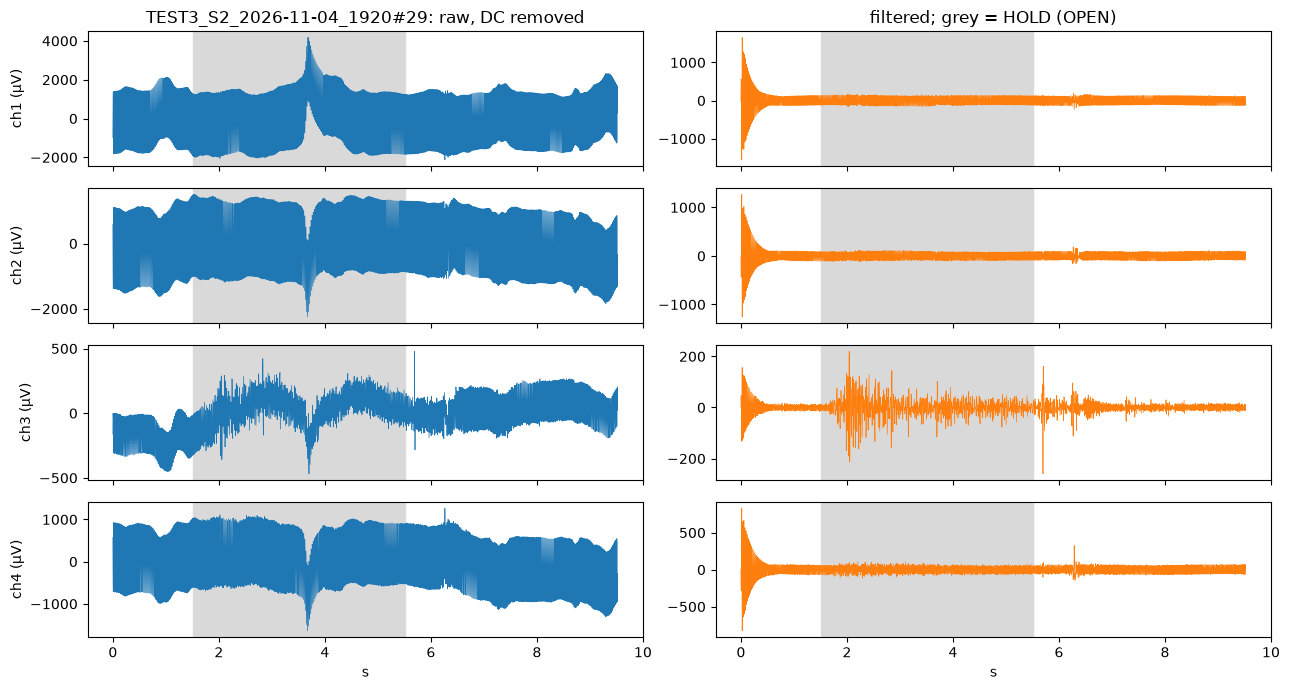

In [2]:
def make_filters(fs):
    sos = [signal.butter(4, BAND_HZ, btype="bandpass", fs=fs, output="sos")]
    for f0 in NOTCH_HZ:
        b, a = signal.iirnotch(f0, Q=30.0, fs=fs)
        sos.append(signal.tf2sos(b, a))
    return np.vstack(sos)


SOS = make_filters(FS)


def causal_filter(x):
    """x: (samples, channels) raw µV -> filtered µV, causal, started at steady state."""
    zi = signal.sosfilt_zi(SOS)[:, :, None] * x[0][None, None, :]
    y, _ = signal.sosfilt(SOS, x, axis=0, zi=zi)
    return y


splits = {name: pd.read_csv(SPLIT_DIR / f"{name}.csv", keep_default_na=False,
                            dtype={"phase": str, "label": str})
          for name in ("train", "val", "test")}
for name, df in splits.items():
    print(f"{name:<5} {len(df):>7} rows, {df['trial_uid'].nunique()} trials")

# one trial before and after filtering
uid = splits["train"]["trial_uid"].iloc[0]
tr = splits["train"][splits["train"]["trial_uid"] == uid]
raw = tr[CHANNELS].to_numpy(float)
filt = causal_filter(raw)
t = np.arange(len(tr)) / FS
fig, axes = plt.subplots(len(CHANNELS), 2, figsize=(13, 7), sharex=True)
for k, ch in enumerate(CHANNELS):
    axes[k, 0].plot(t, raw[:, k] - raw[:, k].mean(), lw=0.5)
    axes[k, 1].plot(t, filt[:, k], lw=0.5, color="C1")
    axes[k, 0].set_ylabel(f"{ch} (µV)")
hold = (tr["phase"] == "HOLD").to_numpy()
for ax in axes.ravel():
    ax.axvspan(t[hold][0], t[hold][-1], color="0.85", zorder=0)
axes[0, 0].set_title(f"{uid}: raw, DC removed")
axes[0, 1].set_title(f"filtered; grey = HOLD ({tr.loc[tr['phase'] == 'HOLD', 'label'].iloc[0]})")
axes[-1, 0].set_xlabel("s"); axes[-1, 1].set_xlabel("s")
plt.tight_layout(); plt.show()

## 2. Standard EMG features per frame

For a frame $x_1 \dots x_N$ of one channel:

| feature | definition | what it captures |
|---|---|---|
| MAV | $\frac{1}{N}\sum \lvert x_i \rvert$ | amplitude, i.e. contraction level |
| RMS | $\sqrt{\frac{1}{N}\sum x_i^2}$ | amplitude (power) |
| WL | $\sum \lvert x_{i+1}-x_i \rvert$ | amplitude and frequency together |
| ZC | sign changes with $\lvert x_{i+1}-x_i \rvert \ge T$ | frequency content |
| SSC | slope changes with $(x_i-x_{i-1})(x_i-x_{i+1}) \ge T^2$ | frequency content |

The threshold $T$ keeps noise from counting as crossings. Amplitude features are log-scaled,
because EMG amplitude spans orders of magnitude between rest and a strong grip. ZC and SSC are
divided by the frame length. All features are then standardised with the train mean and SD.

A frame gets a label only if all its samples carry the same label and at least `SETTLE_S` have
passed since the last label change. A CNN input is 8 consecutive labelled frames of one label.

In [3]:
def frame_features(frames):
    """frames: (n, channels, FRAME_LEN) filtered µV -> (n, channels * 5), channel-major."""
    d = np.diff(frames, axis=-1)
    mav = np.abs(frames).mean(-1)
    rms = np.sqrt((frames ** 2).mean(-1))
    wl = np.abs(d).sum(-1)
    zc = ((frames[..., :-1] * frames[..., 1:] < 0) & (np.abs(d) >= THRESHOLD_UV)).sum(-1)
    ssc = ((d[..., :-1] * -d[..., 1:]) >= THRESHOLD_UV ** 2).sum(-1)
    feats = np.stack([np.log1p(mav), np.log1p(rms), np.log1p(wl),
                      zc / FRAME_LEN, ssc / FRAME_LEN], axis=-1)      # (n, channels, 5)
    return feats.reshape(len(frames), -1)


def trial_frames(tr):
    """Features and labels of the frames of one trial (label None = not usable)."""
    x = causal_filter(tr[CHANNELS].to_numpy(float))
    labels = tr["label"].to_numpy()
    change = np.r_[0, np.flatnonzero(labels[1:] != labels[:-1]) + 1]
    since = np.arange(len(labels)) - change[np.searchsorted(change, np.arange(len(labels)), "right") - 1]
    frames = sliding_window_view(x, FRAME_LEN, axis=0)[::HOP]          # (n, channels, FRAME_LEN)
    starts = np.arange(len(frames)) * HOP
    out_labels = []
    for s0 in starts:
        lab = labels[s0:s0 + FRAME_LEN]
        ok = (lab == lab[0]).all() and lab[0] in CLASSES and since[s0] >= SETTLE_S * FS
        out_labels.append(lab[0] if ok else None)
    return frame_features(frames), np.array(out_labels, dtype=object)


def make_windows(df):
    """CNN inputs (n, N_FRAMES, features), class index (n,), trial uid (n,)."""
    X, y, uids = [], [], []
    for uid, tr in df.groupby("trial_uid", sort=False):
        f, lab = trial_frames(tr)
        for i in range(len(f) - N_FRAMES + 1):
            w = lab[i:i + N_FRAMES]
            if w[0] is not None and all(v == w[0] for v in w):
                X.append(f[i:i + N_FRAMES]); y.append(CLASSES.index(w[0])); uids.append(uid)
    return np.array(X, np.float32), np.array(y, np.int64), np.array(uids)


data = {name: make_windows(df) for name, df in splits.items()}
feat_names = [f"{ch}_{f}" for ch in CHANNELS for f in FEATURES]

mu = data["train"][0].reshape(-1, len(feat_names)).mean(0)
sd = data["train"][0].reshape(-1, len(feat_names)).std(0) + 1e-6
X_train, y_train, _ = data["train"]
X_val, y_val, _ = data["val"]
X_test, y_test, uid_test = data["test"]
X_train, X_val, X_test = [(X - mu) / sd for X in (X_train, X_val, X_test)]

print(f"input shape: {X_train.shape[1:]} (frames x features)")
print("windows per class:")
print(pd.DataFrame({name: np.bincount(data[name][1], minlength=len(CLASSES))
                    for name in data}, index=CLASSES).to_string())

input shape: (8, 20) (frames x features)
windows per class:
       train  val  test
REST    2208  551   552
OPEN     736  184   184
CLOSE    736  184   184
INDEX    736  184   184


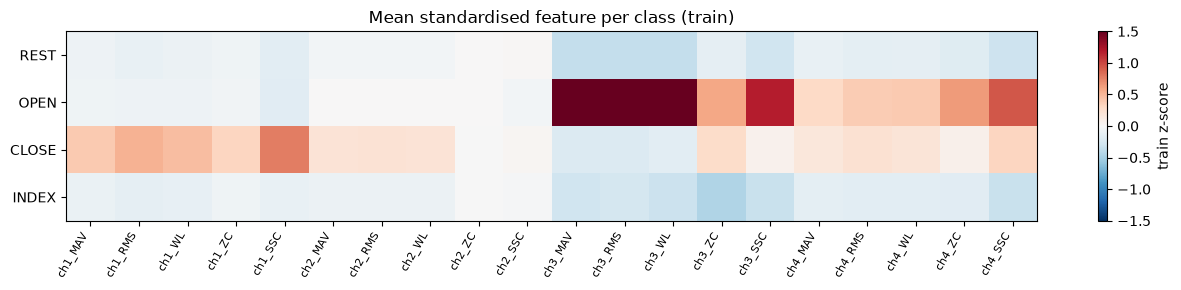

In [4]:
# mean feature value (standardised) per class on the train split
Xf = X_train.mean(axis=1)
mean_by_class = pd.DataFrame([Xf[y_train == k].mean(0) for k in range(len(CLASSES))],
                             index=CLASSES, columns=feat_names)
fig, ax = plt.subplots(figsize=(13, 3))
im = ax.imshow(mean_by_class.to_numpy(), cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(feat_names)), feat_names, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(CLASSES)), CLASSES)
fig.colorbar(im, ax=ax, label="train z-score")
ax.set_title("Mean standardised feature per class (train)")
plt.tight_layout(); plt.show()

## 3. The 1D CNN

Small on purpose, so that it fits a microcontroller: two convolution blocks along the 8 frames,
global average pooling, one dense layer. The classes are unbalanced (REST comes from the rest
phase of every trial, about three times as much as each gesture), so the loss is weighted by
class.

In [5]:
def build_model(n_frames, n_feat, n_classes):
    inp = keras.Input((n_frames, n_feat), name="features")
    x = keras.layers.Conv1D(32, 3, padding="same", activation="relu")(inp)
    x = keras.layers.Conv1D(32, 3, padding="same", activation="relu")(x)
    x = keras.layers.MaxPooling1D(2)(x)
    x = keras.layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.GlobalAveragePooling1D()(x)
    x = keras.layers.Dropout(0.3)(x)
    out = keras.layers.Dense(n_classes, activation="softmax", name="probs")(x)
    return keras.Model(inp, out, name="emg_cnn1d")


model = build_model(N_FRAMES, X_train.shape[2], len(CLASSES))
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)
class_weight = dict(enumerate(weights))
print("class weights:", {CLASSES[k]: round(float(w), 2) for k, w in class_weight.items()})

history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=class_weight,
                    shuffle=True, verbose=2)

Model: "emg_cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 8, 20)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 8, 32)          │         1,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 8, 32)          │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 4, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 4, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,524 (45.02 KB)

 Trainable params: 11,524 (45.02 KB)

 Non-trainable params: 0 (0.00 B)

class weights: {'REST': 0.5, 'OPEN': 1.5, 'CLOSE': 1.5, 'INDEX': 1.5}
Epoch 1/15


... (25 outputs left out)

Epoch 14/15


138/138 - 0s - 2ms/step - accuracy: 0.8743 - loss: 0.2241 - val_accuracy: 0.7135 - val_loss: 0.9907


Epoch 15/15


138/138 - 0s - 2ms/step - accuracy: 0.8931 - loss: 0.1963 - val_accuracy: 0.7008 - val_loss: 1.1110


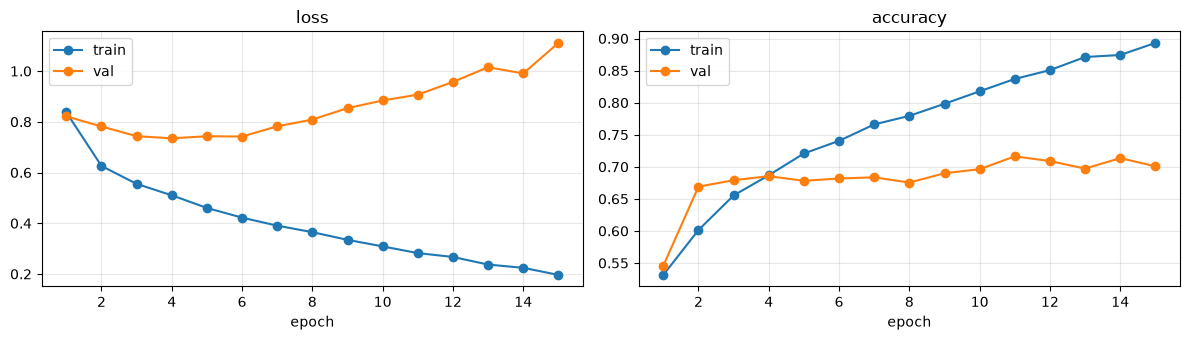

In [6]:
h = history.history
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
epochs = np.arange(1, EPOCHS + 1)
axes[0].plot(epochs, h["loss"], "o-", label="train"); axes[0].plot(epochs, h["val_loss"], "o-", label="val")
axes[1].plot(epochs, h["accuracy"], "o-", label="train"); axes[1].plot(epochs, h["val_accuracy"], "o-", label="val")
axes[0].set_title("loss"); axes[1].set_title("accuracy")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 4. Evaluation on the test split

Window accuracy counts every 576 ms input. Trial accuracy takes the majority vote of the
windows of the HOLD part of each test trial, which is closer to "did it recognise the grip".

In [7]:
def report(name, pred):
    print(f"{name}: window accuracy {accuracy_score(y_test, pred):.3f}")
    print(classification_report(y_test, pred, labels=range(len(CLASSES)), target_names=CLASSES,
                                digits=3, zero_division=0))


def trial_accuracy(pred):
    rows = []
    for uid in np.unique(uid_test):
        m = (uid_test == uid) & (y_test != CLASSES.index("REST"))
        if m.any():
            rows.append(np.bincount(pred[m], minlength=len(CLASSES)).argmax() == y_test[m][0])
    return float(np.mean(rows)), len(rows)


def plot_confusion(pred, title, ax):
    cm = confusion_matrix(y_test, pred, labels=range(len(CLASSES)), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(CLASSES)), CLASSES); ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)


probs_keras = model.predict(X_test, batch_size=256, verbose=0)
pred_keras = probs_keras.argmax(1)
report("Keras float32", pred_keras)
acc_t, n_t = trial_accuracy(pred_keras)
print(f"trial accuracy (majority vote over the hold): {acc_t:.3f} on {n_t} trials")

Keras float32: window accuracy 0.636
              precision    recall  f1-score   support

        REST      0.667     0.676     0.671       552
        OPEN      0.822     0.951     0.882       184
       CLOSE      0.435     0.603     0.506       184
       INDEX      0.558     0.234     0.330       184

    accuracy                          0.636      1104
   macro avg      0.621     0.616     0.597      1104
weighted avg      0.636     0.636     0.622      1104

trial accuracy (majority vote over the hold): 0.583 on 12 trials


## 5. Export and quantisation

Three versions of the same network:

- **Keras** model file (float32, includes the training state)
- **TFLite float32**: the inference graph only
- **TFLite int8** (full-integer post-training quantisation): weights and activations in 8 bits.
  The scales of the activations are calibrated on a representative set of train inputs. Input
  and output are int8 too, which is what TensorFlow Lite Micro on a microcontroller expects.

The test split is run through the two TFLite models with the TFLite interpreter.

In [8]:
keras_path = OUT_DIR / "emg_cnn1d.keras"
model.save(keras_path)


def converter_for(m):
    return tf.lite.TFLiteConverter.from_keras_model(m)


conv = converter_for(model)
tfl_float = conv.convert()

rng = np.random.default_rng(SEED)
rep_idx = rng.choice(len(X_train), size=min(500, len(X_train)), replace=False)


def representative_data():
    for i in rep_idx:
        yield [X_train[i:i + 1]]


conv = converter_for(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = representative_data
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8
conv.inference_output_type = tf.int8
tfl_int8 = conv.convert()

float_path, int8_path = OUT_DIR / "emg_cnn1d_float32.tflite", OUT_DIR / "emg_cnn1d_int8.tflite"
float_path.write_bytes(tfl_float)
int8_path.write_bytes(tfl_int8)

# feature parameters needed to run the model elsewhere (e.g. on the board)
(OUT_DIR / "features.json").write_text(json.dumps({
    "fs": FS, "channels": CHANNELS, "classes": CLASSES, "band_hz": BAND_HZ, "notch_hz": NOTCH_HZ,
    "frame_len": FRAME_LEN, "hop": HOP, "n_frames": N_FRAMES, "threshold_uv": THRESHOLD_UV,
    "features": FEATURES, "feature_order": feat_names,
    "amplitude_transform": "log1p (MAV, RMS, WL); ZC, SSC divided by frame_len",
    "mean": mu.tolist(), "sd": sd.tolist(), "split": str(SPLIT_DIR), "seed": SEED}, indent=2),
    encoding="utf-8")


def run_tflite(model_bytes, X):
    interp = tf.lite.Interpreter(model_content=model_bytes)
    interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    in_scale, in_zero = inp["quantization"]
    out_scale, out_zero = out["quantization"]
    probs = np.empty((len(X), int(out["shape"][-1])), np.float32)
    t0 = time.perf_counter()
    for i in range(len(X)):
        x = X[i:i + 1]
        if inp["dtype"] == np.int8:
            x = np.clip(np.round(x / in_scale + in_zero), -128, 127).astype(np.int8)
        interp.set_tensor(inp["index"], x)
        interp.invoke()
        y = interp.get_tensor(out["index"])[0]
        probs[i] = (y.astype(np.float32) - out_zero) * out_scale if out["dtype"] == np.int8 else y
    per_call_ms = (time.perf_counter() - t0) / len(X) * 1e3
    return probs, per_call_ms, inp, out


probs_float, ms_float, _, _ = run_tflite(tfl_float, X_test)
probs_int8, ms_int8, inp8, out8 = run_tflite(tfl_int8, X_test)
pred_float, pred_int8 = probs_float.argmax(1), probs_int8.argmax(1)
print("int8 input quantisation (scale, zero point):", inp8["quantization"])
print("int8 output quantisation (scale, zero point):", out8["quantization"])

INFO:tensorflow:Assets written to: C:\Users\Gabri\AppData\Local\Temp\tmp3zxbmwzl\assets


INFO:tensorflow:Assets written to: C:\Users\Gabri\AppData\Local\Temp\tmp3zxbmwzl\assets


Saved artifact at 'C:\Users\Gabri\AppData\Local\Temp\tmp3zxbmwzl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8, 20), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  2729131809232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729131809616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729131809424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729131809040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729132028176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729132019728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729135354896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729135354704: TensorSpec(shape=(), dtype=tf.resource, name=None)


INFO:tensorflow:Assets written to: C:\Users\Gabri\AppData\Local\Temp\tmpzwq515rv\assets


INFO:tensorflow:Assets written to: C:\Users\Gabri\AppData\Local\Temp\tmpzwq515rv\assets


Saved artifact at 'C:\Users\Gabri\AppData\Local\Temp\tmpzwq515rv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8, 20), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  2729131809232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729131809616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729131809424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729131809040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729132028176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729132019728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729135354896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2729135354704: TensorSpec(shape=(), dtype=tf.resource, name=None)


C:\File\AeaSapiens\20262027\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


C:\File\AeaSapiens\20262027\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


int8 input quantisation (scale, zero point): (0.06696373224258423, 1)
int8 output quantisation (scale, zero point): (0.00390625, -128)


## 6. Size and accuracy: float32 vs int8

In [9]:
n_params = model.count_params()
rows = []
for name, size, pred, ms in (
        ("Keras file (float32)", keras_path.stat().st_size, pred_keras, None),
        ("TFLite float32", len(tfl_float), pred_float, ms_float),
        ("TFLite int8", len(tfl_int8), pred_int8, ms_int8)):
    rows.append({"model": name, "size_kB": round(size / 1024, 1),
                 "test_window_acc": round(accuracy_score(y_test, pred), 3),
                 "test_trial_acc": round(trial_accuracy(pred)[0], 3),
                 "agrees_with_keras": round(float((pred == pred_keras).mean()), 3),
                 "PC_ms_per_input": None if ms is None else round(ms, 3)})
comparison = pd.DataFrame(rows).set_index("model")
print(f"parameters: {n_params:,}  -> float32 weights {n_params * 4 / 1024:.1f} kB, "
      f"int8 weights {n_params / 1024:.1f} kB")
print(f"TFLite int8 is {len(tfl_float) / len(tfl_int8):.1f}x smaller than TFLite float32")
print(f"max |probability difference| int8 vs float32: {np.abs(probs_int8 - probs_float).max():.3f}")
comparison

parameters: 11,524  -> float32 weights 45.0 kB, int8 weights 11.3 kB
TFLite int8 is 2.4x smaller than TFLite float32
max |probability difference| int8 vs float32: 0.340


,size_kB,test_window_acc,test_trial_acc,agrees_with_keras,PC_ms_per_input
model,,,,,
Keras file (float32),174.9,0.636,0.583,1.000,NaN
TFLite float32,50.8,0.636,0.583,1.000,0.007
TFLite int8,21.3,0.639,0.500,0.981,0.010


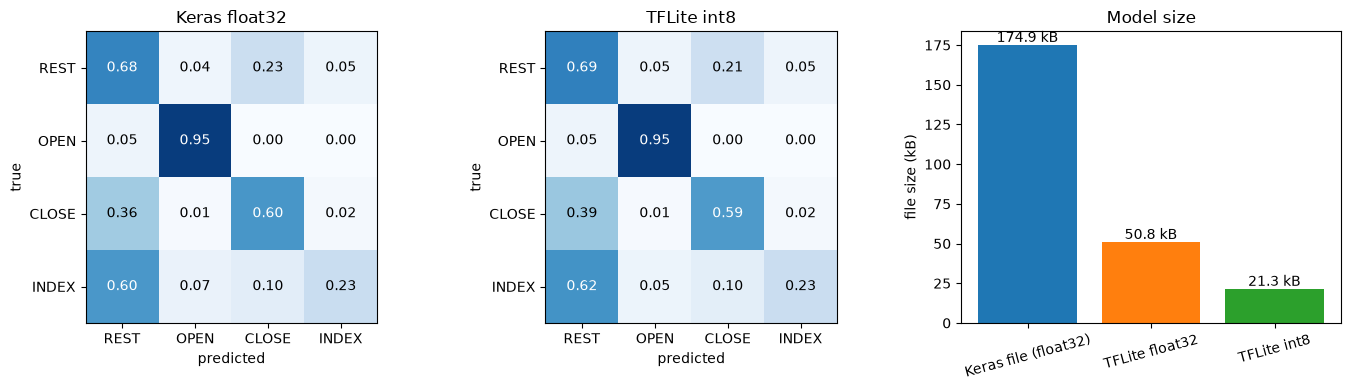

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_confusion(pred_keras, "Keras float32", axes[0])
plot_confusion(pred_int8, "TFLite int8", axes[1])
names = comparison.index.tolist()
axes[2].bar(names, comparison["size_kB"], color=["C0", "C1", "C2"])
for i, v in enumerate(comparison["size_kB"]):
    axes[2].text(i, v, f"{v} kB", ha="center", va="bottom")
axes[2].set_ylabel("file size (kB)"); axes[2].set_title("Model size")
axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## Notes on Part 1

- Only two sessions of one subject on one day, and 12 test trials: the scores are a first look,
  not a performance estimate. A test on another day (electrodes placed again) will be lower.
- The PC timings only compare the two models; they say nothing about the time on the board.
- The model reads 576 ms of signal, so a decision lags the movement by up to about that much.
  `N_FRAMES`, `FRAME_LEN` and `HOP` set this trade-off.
- The feature parameters (filters, frames, mean and SD) are in `emg_cnn/features.json`; the
  board must compute exactly the same features before feeding the int8 model.

# Part 2: binary CLOSE detector for the first prototype

The first hand prototype has two states, so the task becomes binary:

- class 1, **CLOSE**: the hand closes;
- class 0, **NOT_CLOSE**: REST or OPEN, the hand stays open.

INDEX trials are dropped completely (their hold and the rest after it): the prototype protocol has
no INDEX, and their rest periods would only add rest that follows a gesture the prototype never
sees. The trials are the same as in Part 1 minus the INDEX ones, so the test trials are still
unseen by every model in this notebook.

Everything has to run in real time on one microcontroller core, so the pipeline is kept to
causal IIR filters, a handful of sums per frame and a very small network.

## 7. Binary task and data

In [11]:
# ---- Part 2 settings ----
B_CLASSES = ["NOT_CLOSE", "CLOSE"]           # 0 = REST or OPEN (hand open), 1 = CLOSE
B_LABELS = ("REST", "OPEN", "CLOSE")          # source labels that are kept
B_BAND_HZ = BAND_HZ                           # band-pass, as in Part 1
B_STOP_HZ = (45.0, 55.0)                      # mains band-stop, replaces the narrow 50 Hz notch (section 8)
B_HARMONIC = (100.0, 10.0)                    # notch at the first mains harmonic: frequency, Q
B_THRESHOLD_UV = THRESHOLD_UV                 # dead band of ZC and SSC, as in Part 1
ALL_FEATURES = ["MAV", "RMS", "WL", "ZC", "SSC"]  # candidates looked at in section 8
B_FEATURES = ["MAV", "WL", "ZC", "SSC"]       # chosen in section 8
B_N_FRAMES = N_FRAMES                         # frames per input; may be changed by the search (section 10)
CAL_SKIP_S = 1.0                              # skipped at the start of the calibration rest
B_THRESHOLD = 0.5                             # decision threshold on P(CLOSE)
CV_FOLDS, CV_EPOCHS, CV_BATCH = 5, 40, 64
B_OUT_DIR = Path("emg_bin")                   # exported binary model and feature parameters
B_OUT_DIR.mkdir(exist_ok=True)
SESSION_ROOT = SPLIT_DIR.parents[2]           # session folders in split.json are relative to it
tf.get_logger().setLevel("ERROR")             # silence retracing warnings of the many small fits


def hold_gesture(df):
    return df[df["phase"] == "HOLD"].groupby("trial_uid", sort=False)["label"].first()


b_splits = {}
for name, df in splits.items():
    g = hold_gesture(df)
    b_splits[name] = df[df["trial_uid"].isin(g[g != "INDEX"].index)]
    print(f"{name:<5} {b_splits[name]['trial_uid'].nunique():>2} trials {g[g != 'INDEX'].value_counts().to_dict()}")

train 32 trials {'OPEN': 16, 'CLOSE': 16}
val    8 trials {'OPEN': 4, 'CLOSE': 4}
test   8 trials {'OPEN': 4, 'CLOSE': 4}


## 8. Data inspection and choice of the features

### 8.1 Spectra of the three postures

Power spectral density of the settled REST, OPEN and CLOSE segments of the train trials, with
only a 5 Hz high-pass (zero-phase, for inspection only). EMG from a contraction is broadband,
roughly 20 to 150 Hz, so it should show up as a raised floor across the band. Narrow peaks are
interference.

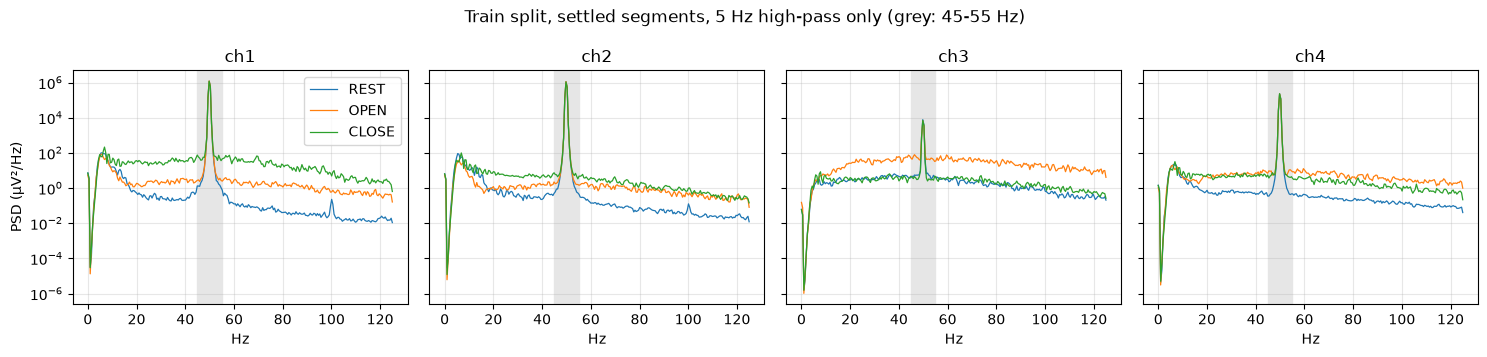

mains peak at 49.80 Hz (bin width 0.49 Hz)
REST PSD around 50 Hz, ch1 (µV²/Hz): {45.4: 1, 45.9: 1, 46.4: 2, 46.9: 3, 47.4: 5, 47.9: 16, 48.3: 73, 48.8: 753, 49.3: 135802, 49.8: 1186936, 50.3: 594413, 50.8: 4753, 51.3: 193, 51.8: 27, 52.2: 9, 52.7: 3, 53.2: 2, 53.7: 2, 54.2: 1, 54.7: 1}

mains amplitude, median RMS of 48-52 Hz over the train trials (µV):
                             ch1    ch2   ch3    ch4
session                                             
TEST2_S2_2026-11-04_1854   767.0  979.0  64.0  165.0
TEST3_S2_2026-11-04_1920  1173.0  913.0  84.0  580.0


In [12]:
def settled_segments(tr, skip_s=SETTLE_S):
    # (label, start, stop) of every run of one label in B_LABELS, without its first skip_s
    lab = tr["label"].to_numpy()
    edges = np.r_[0, np.flatnonzero(lab[1:] != lab[:-1]) + 1, len(lab)]
    skip = int(skip_s * FS)
    return [(lab[a], a + skip, b) for a, b in zip(edges[:-1], edges[1:])
            if lab[a] in B_LABELS and b - a > skip + 512]


HP_INSPECT = signal.butter(4, 5.0, btype="highpass", fs=FS, output="sos")
psd = {lab: [] for lab in B_LABELS}
for uid, tr in b_splits["train"].groupby("trial_uid", sort=False):
    x = signal.sosfiltfilt(HP_INSPECT, tr[CHANNELS].to_numpy(float), axis=0)
    for lab, a, b in settled_segments(tr):
        f_psd, p = signal.welch(x[a:b], fs=FS, nperseg=512, axis=0)
        psd[lab].append(p)
psd = {lab: np.mean(v, axis=0) for lab, v in psd.items()}

fig, axes = plt.subplots(1, len(CHANNELS), figsize=(15, 3.6), sharey=True)
for k, ch in enumerate(CHANNELS):
    for lab in B_LABELS:
        axes[k].semilogy(f_psd, psd[lab][:, k], lw=0.9, label=lab)
    axes[k].axvspan(*B_STOP_HZ, color="0.9", zorder=0)
    axes[k].set_title(ch); axes[k].set_xlabel("Hz"); axes[k].grid(alpha=0.3)
axes[0].set_ylabel("PSD (µV²/Hz)"); axes[0].legend()
fig.suptitle("Train split, settled segments, 5 Hz high-pass only (grey: 45-55 Hz)")
plt.tight_layout(); plt.show()

band = (f_psd > 45) & (f_psd < 55)
print(f"mains peak at {f_psd[band][np.argmax(psd['REST'][band].mean(1))]:.2f} Hz "
      f"(bin width {f_psd[1] - f_psd[0]:.2f} Hz)")
print("REST PSD around 50 Hz, ch1 (µV²/Hz):",
      {round(float(f), 1): round(float(p)) for f, p in zip(f_psd[band], psd["REST"][band, 0])})

BP_MAINS = signal.butter(4, (48.0, 52.0), btype="bandpass", fs=FS, output="sos")
rows = []
for uid, tr in b_splits["train"].groupby("trial_uid", sort=False):
    m = signal.sosfiltfilt(BP_MAINS, tr[CHANNELS].to_numpy(float), axis=0)
    rows.append([tr["session"].iloc[0], *np.sqrt((m ** 2).mean(0))])
print("\nmains amplitude, median RMS of 48-52 Hz over the train trials (µV):")
print(pd.DataFrame(rows, columns=["session", *CHANNELS]).groupby("session").median().round(0).to_string())

### 8.2 Mains rejection: notch or band-stop

The mains line is huge: about 0.8-1.2 mV RMS on ch1 and ch2 and 0.2-0.6 mV on ch4, against a
few µV of resting EMG after filtering. It also peaks a little below 50.0 Hz (49.8 Hz) and is
spread over about 49.3 to 50.8 Hz, so the narrow Part 1 notch (Q = 30, -3 dB width 1.7 Hz) takes
only 3 to 13 dB off most of it (the printout below); its deep null is exactly at 50.0 Hz, where
there is little power. What is left is larger than the EMG of a grip, so the amplitude features
of ch1 and ch2 mostly measure mains.

Part 2 therefore uses a 2nd-order Butterworth **band-stop 45-55 Hz** (two biquads) instead. It
removes a 10 Hz slice of EMG, but EMG is broadband and the rest of the 20-110 Hz band carries the
same information. The cost on the board is one more biquad per channel than Part 1.

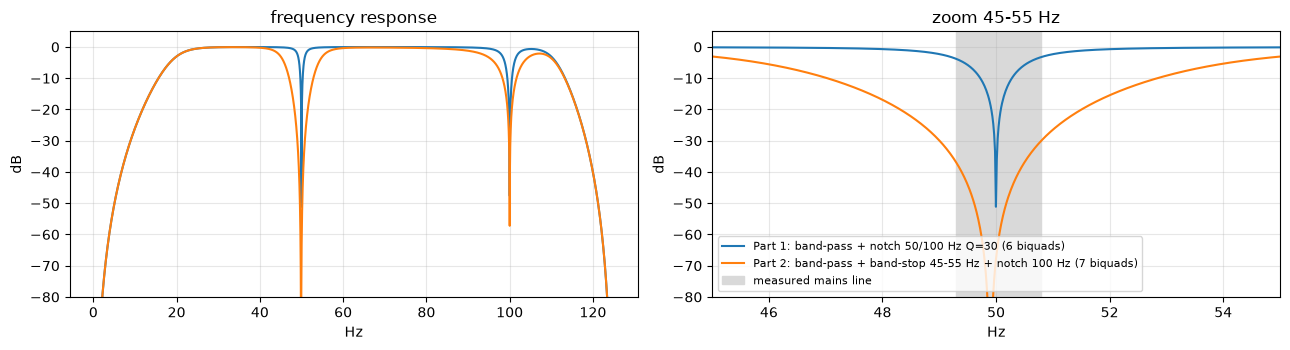

attenuation (dB) at [49.3, 49.5, 49.8, 50.0, 50.3, 50.8] Hz
  Part 1: [-3.8, -5.8, -12.6, -239.9, -9.4, -3.2]
  Part 2: [-37.0, -44.1, -68.6, -67.6, -43.9, -29.9]


In [13]:
def make_binary_filter(fs):
    sos = [signal.butter(4, B_BAND_HZ, btype="bandpass", fs=fs, output="sos"),
           signal.butter(2, B_STOP_HZ, btype="bandstop", fs=fs, output="sos")]
    b, a = signal.iirnotch(B_HARMONIC[0], Q=B_HARMONIC[1], fs=fs)
    sos.append(signal.tf2sos(b, a))
    return np.vstack(sos)


B_SOS = make_binary_filter(FS)


def filter_with(sos, x):
    # causal filter of x (samples, channels), state started at the steady state of the first sample
    zi = signal.sosfilt_zi(sos)[:, :, None] * x[0][None, None, :]
    return signal.sosfilt(sos, x, axis=0, zi=zi)[0]


f_h = np.linspace(0.5, FS / 2 - 0.5, 8000)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
rows = {}
for sos_, name in ((SOS, f"Part 1: band-pass + notch 50/100 Hz Q=30 ({len(SOS)} biquads)"),
                   (B_SOS, f"Part 2: band-pass + band-stop 45-55 Hz + notch 100 Hz ({len(B_SOS)} biquads)")):
    _, h = signal.sosfreqz(sos_, worN=f_h, fs=FS)
    db = 20 * np.log10(np.abs(h) + 1e-12)
    for ax in axes:
        ax.plot(f_h, db, label=name)
    _, h_line = signal.sosfreqz(sos_, worN=np.array([49.3, 49.5, 49.8, 50.0, 50.3, 50.8]), fs=FS)
    rows[name.split(":")[0]] = np.round(20 * np.log10(np.abs(h_line) + 1e-12), 1)
axes[0].set_ylim(-80, 5); axes[0].set_title("frequency response")
axes[1].set_xlim(45, 55); axes[1].set_ylim(-80, 5); axes[1].set_title("zoom 45-55 Hz")
axes[1].axvspan(49.3, 50.8, color="0.85", zorder=0, label="measured mains line")
for ax in axes:
    ax.set_xlabel("Hz"); ax.set_ylabel("dB"); ax.grid(alpha=0.3)
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()
print("attenuation (dB) at", [49.3, 49.5, 49.8, 50.0, 50.3, 50.8], "Hz")
for name, v in rows.items():
    print(f"  {name}: {v.tolist()}")

### 8.3 Separability of each feature, old and new filter

The five Part 1 features are computed on the same 32-sample frames with both filters. For each
feature and channel, the AUC says how well that single number separates CLOSE frames from
REST + OPEN frames (train split, settled frames): 0.5 means no information, 1 (or 0) a perfect
split with CLOSE above (or below).

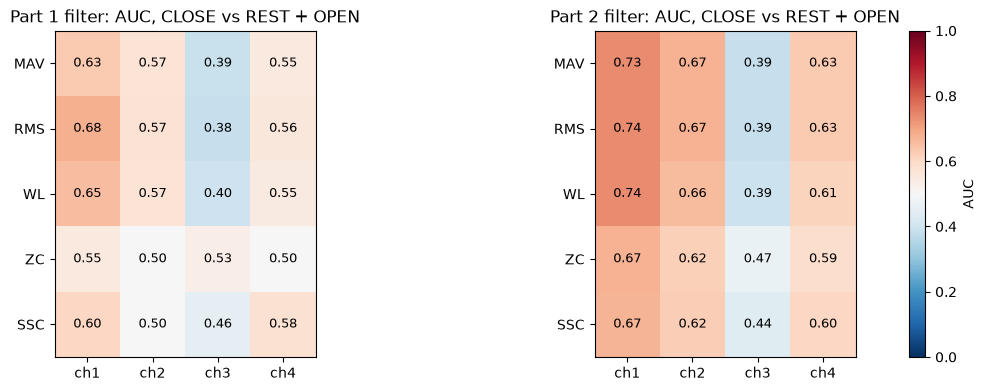

median MAV per frame (µV), train:
                      ch1   ch2   ch3   ch4
Part 1 filter REST   78.4  77.6   9.0  31.8
              OPEN   79.6  76.3  38.8  36.4
              CLOSE  88.3  82.6  10.5  34.6
Part 2 filter REST    1.5   2.0   5.9   3.2
              OPEN    7.9   6.1  35.0  14.2
              CLOSE  15.2   6.2   6.2   8.7


In [14]:
def frame_feature_array(frames, threshold):
    # frames (n, channels, L) filtered µV -> (n, channels, 5) in ALL_FEATURES order
    L = frames.shape[-1]
    d = np.diff(frames, axis=-1)
    mav = np.abs(frames).mean(-1)
    rms = np.sqrt((frames ** 2).mean(-1))
    wl = np.abs(d).sum(-1)
    zc = ((frames[..., :-1] * frames[..., 1:] < 0) & (np.abs(d) >= threshold)).sum(-1)
    ssc = ((d[..., :-1] * -d[..., 1:]) >= threshold ** 2).sum(-1)
    return np.stack([np.log1p(mav), np.log1p(rms), np.log1p(wl), zc / L, ssc / L], axis=-1)


def usable_frame_labels(labels):
    # label of every frame; None if mixed, not in B_LABELS, or within SETTLE_S of a label change
    change = np.r_[0, np.flatnonzero(labels[1:] != labels[:-1]) + 1]
    idx = np.arange(len(labels))
    since = idx - change[np.searchsorted(change, idx, "right") - 1]
    out = []
    for s0 in range(0, len(labels) - FRAME_LEN + 1, HOP):
        lab = labels[s0:s0 + FRAME_LEN]
        ok = (lab == lab[0]).all() and lab[0] in B_LABELS and since[s0] >= SETTLE_S * FS
        out.append(lab[0] if ok else None)
    return np.array(out, dtype=object)


def trial_feature_frames(df, sos, threshold=B_THRESHOLD_UV):
    # per trial: features of all frames (n, channels, 5), frame labels, session
    out = []
    for uid, tr in df.groupby("trial_uid", sort=False):
        x = filter_with(sos, tr[CHANNELS].to_numpy(float))
        frames = sliding_window_view(x, FRAME_LEN, axis=0)[::HOP]
        out.append({"uid": uid, "session": tr["session"].iloc[0],
                    "feats": frame_feature_array(frames, threshold),
                    "labels": usable_frame_labels(tr["label"].to_numpy())})
    return out


def frame_dataset(trials):
    # settled frames only: features (n, channels, 5), label, session
    F = np.concatenate([t["feats"] for t in trials])
    lab = np.concatenate([t["labels"] for t in trials])
    sess = np.concatenate([[t["session"]] * len(t["labels"]) for t in trials])
    keep = np.array([v is not None for v in lab])
    return F[keep], lab[keep].astype(str), sess[keep]


insp_trials = {"Part 1 filter": trial_feature_frames(b_splits["train"], SOS),
               "Part 2 filter": trial_feature_frames(b_splits["train"], B_SOS)}
insp = {name: frame_dataset(t) for name, t in insp_trials.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, (name, (F, lab, _)) in zip(axes, insp.items()):
    auc = np.array([[roc_auc_score(lab == "CLOSE", F[:, c, k]) for c in range(len(CHANNELS))]
                    for k in range(len(ALL_FEATURES))])
    im = ax.imshow(auc, cmap="RdBu_r", vmin=0, vmax=1)
    for k in range(len(ALL_FEATURES)):
        for c in range(len(CHANNELS)):
            ax.text(c, k, f"{auc[k, c]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(CHANNELS)), CHANNELS); ax.set_yticks(range(len(ALL_FEATURES)), ALL_FEATURES)
    ax.set_title(f"{name}: AUC, CLOSE vs REST + OPEN")
fig.colorbar(im, ax=list(axes), label="AUC")
plt.show()

med = {}
for name, (F, lab, _) in insp.items():
    for l in B_LABELS:
        med[(name, l)] = np.expm1(np.median(F[lab == l][:, :, 0], axis=0))
print("median MAV per frame (µV), train:")
print(pd.DataFrame(med, index=CHANNELS).T.round(1).to_string())

With the Part 1 filter the resting MAV of ch1 and ch2 is mostly mains residue, and a grip barely
moves it. With the band-stop, resting MAV drops to a few µV and CLOSE stands well above it on
ch1. ch3 is the channel that sees OPEN (MAV 35 µV against 6 µV; its AUC is below 0.5 because
OPEN belongs to the negative class), so it helps the model tell OPEN from CLOSE although it
barely sees CLOSE.

### 8.4 Redundancy between the features

Correlation between the five features of the same channel (train frames, Part 2 filter,
averaged over the channels).

In [15]:
F, lab, _ = insp["Part 2 filter"]
corr = np.mean([np.corrcoef(F[:, c, :].T) for c in range(len(CHANNELS))], axis=0)
print(pd.DataFrame(corr, index=ALL_FEATURES, columns=ALL_FEATURES).round(2).to_string())

      MAV   RMS    WL    ZC   SSC
MAV  1.00  1.00  0.99  0.85  0.90
RMS  1.00  1.00  0.99  0.85  0.90
WL   0.99  0.99  1.00  0.89  0.93
ZC   0.85  0.85  0.89  1.00  0.92
SSC  0.90  0.90  0.93  0.92  1.00


MAV, RMS and WL are almost the same number (amplitude). RMS also needs a square root per frame,
so it is the first candidate to drop. ZC and SSC are correlated with amplitude too (0.85-0.93),
because with the clean filter the resting signal stays mostly inside the 5 µV dead band: they
count crossings and turns larger than the dead band, which appear when there is muscle activity.
They are not redundant, though: section 8.6 shows they still add information.

### 8.5 Session baseline and calibration

The two sessions differ: electrode contact and mains pick-up change every time the electrodes
are placed, and this shifts the log-amplitude features of every class. Every session starts with
a 10 s calibration rest (marker 20, before the first calibration cue), which is not part of any
trial. Its mean feature vector is a per-session baseline; subtracting it turns the log-amplitude
features into "activation relative to this session's rest". On the board this is the same thing:
ask for 10 s of rest at start-up, average the features, subtract from then on.

In [16]:
def calibration_rest(session):
    # raw samples of the calibration rest of a session: from marker 20 to the next marker
    info = next(s for s in manifest["sessions"] if s["name"] == session)
    path = SESSION_ROOT / Path(*PureWindowsPath(info["folder"]).parts) / "emg.csv"
    emg = pd.read_csv(path, usecols=["marker", *CHANNELS])
    marker = emg["marker"].to_numpy()
    i0 = int(np.flatnonzero(marker == 20)[0])
    i1 = i0 + 1 + int(np.flatnonzero(marker[i0 + 1:] != 0)[0])
    return emg[CHANNELS].to_numpy(float)[i0:i1]


CAL_RAW = {s["name"]: calibration_rest(s["name"]) for s in manifest["sessions"]}


def session_baselines(sos, threshold=B_THRESHOLD_UV):
    # mean frame features (channels, 5) of each session's calibration rest
    out = {}
    for name, raw in CAL_RAW.items():
        x = filter_with(sos, raw)[int(CAL_SKIP_S * FS):]
        out[name] = frame_feature_array(sliding_window_view(x, FRAME_LEN, axis=0)[::HOP], threshold).mean(0)
    return out


base_old, base_new = session_baselines(SOS), session_baselines(B_SOS)
print("calibration rest:", {k: f"{len(v) / FS:.1f} s" for k, v in CAL_RAW.items()})
print("\ncalibration-rest MAV (µV), Part 2 filter:")
print(pd.DataFrame({s: np.expm1(b[:, 0]) for s, b in base_new.items()}, index=CHANNELS).T.round(2).to_string())

F, lab, sess = insp["Part 2 filter"]
short = [s.split("_")[0] for s in sess]
F_cal = F - np.stack([base_new[s] for s in sess])
tab = pd.concat({
    "log MAV": pd.DataFrame(F[:, :, 0], columns=CHANNELS).assign(session=short, label=lab).groupby(["session", "label"]).mean(),
    "log MAV - calibration rest": pd.DataFrame(F_cal[:, :, 0], columns=CHANNELS).assign(session=short, label=lab).groupby(["session", "label"]).mean(),
}, axis=1)
print("\nmean log MAV per session and posture, train frames:")
print(tab.round(2).to_string())

calibration rest: {'TEST2_S2_2026-11-04_1854': '10.0 s', 'TEST3_S2_2026-11-04_1920': '10.0 s'}

calibration-rest MAV (µV), Part 2 filter:
                           ch1   ch2   ch3   ch4
TEST2_S2_2026-11-04_1854  2.02  2.26  6.24  3.75
TEST3_S2_2026-11-04_1920  0.87  1.61  3.46  2.23



mean log MAV per session and posture, train frames:
              log MAV                   log MAV - calibration rest                  
                  ch1   ch2   ch3   ch4                        ch1   ch2   ch3   ch4
session label                                                                       
TEST2   CLOSE    3.74  2.52  2.65  2.72                       2.63  1.34  0.67  1.16
        OPEN     2.43  2.23  3.86  3.00                       1.33  1.05  1.88  1.44
        REST     1.18  1.17  1.93  1.61                       0.08 -0.02 -0.05  0.05
TEST3   CLOSE    1.27  1.25  1.31  1.62                       0.65  0.29 -0.19  0.44
        OPEN     1.85  1.61  3.12  2.25                       1.23  0.65  1.63  1.08
        REST     0.94  1.25  1.81  1.36                       0.31  0.29  0.32  0.19


Without the baseline, the CLOSE level of TEST3 on ch1 (1.27) is about the REST level of TEST2
(1.18), so no single threshold works for both sessions. After subtracting it, REST sits at 0 in
TEST2 and at 0.2-0.3 in TEST3 (that session's calibration rest was a little quieter than its
trial rests), and TEST3 CLOSE (0.65 on ch1) is clearly above both. The grips of TEST3 were
weaker than those of TEST2 on ch1; calibration does not remove that difference, the model has
to cope with it.

### 8.6 Which features: cross-validated test with a linear model

To choose, each candidate (filter, calibration, feature set) feeds the same simple classifier:
logistic regression on the mean of the 8 frames of an input. The score is the balanced accuracy
(mean of the recall of the two classes, so the 3:1 class imbalance does not inflate it) in a
5-fold cross-validation over the train + val trials. Folds are made of whole trials, so no trial
is split between training and scoring (`StratifiedGroupKFold`, stratified by posture). The test
split is not used.

In [17]:
def windows_from(trials, n_frames, feat_idx, base=None):
    # inputs (n, n_frames, channels*len(feat_idx)) channel-major, binary target, posture, trial uid
    X, src, uids = [], [], []
    for t in trials:
        F = t["feats"] if base is None else t["feats"] - base[t["session"]]
        F = F[:, :, feat_idx].reshape(len(F), -1)
        lab = t["labels"]
        for i in range(len(F) - n_frames + 1):
            w = lab[i:i + n_frames]
            if w[0] is not None and all(v == w[0] for v in w):
                X.append(F[i:i + n_frames]); src.append(w[0]); uids.append(t["uid"])
    src = np.array(src, dtype=str)
    return np.array(X, np.float32), (src == "CLOSE").astype(np.int64), src, np.array(uids)


CV_SPLITTER = StratifiedGroupKFold(CV_FOLDS, shuffle=True, random_state=SEED)
cv_df = pd.concat([b_splits["train"], b_splits["val"]])
cv_frames = {"Part 1 filter": (trial_feature_frames(cv_df, SOS), base_old),
             "Part 2 filter": (trial_feature_frames(cv_df, B_SOS), base_new)}
feature_sets = {"MAV": ["MAV"], "MAV+WL": ["MAV", "WL"], "MAV+ZC+SSC": ["MAV", "ZC", "SSC"],
                "MAV+WL+ZC+SSC": ["MAV", "WL", "ZC", "SSC"], "all five": ALL_FEATURES}
rows = []
for filt_name, (trials, base) in cv_frames.items():
    for cal in (False, True):
        for set_name, feats in feature_sets.items():
            X, y, src, uids = windows_from(trials, N_FRAMES, [ALL_FEATURES.index(f) for f in feats],
                                           base if cal else None)
            Xm = X.mean(axis=1)
            scores = []
            for tri, tei in CV_SPLITTER.split(Xm, src, uids):
                clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000))
                p = clf.fit(Xm[tri], y[tri]).predict_proba(Xm[tei])[:, 1]
                scores.append([balanced_accuracy_score(y[tei], p >= 0.5), roc_auc_score(y[tei], p)])
            s = np.mean(scores, axis=0)
            rows.append({"filter": filt_name, "calibration": "yes" if cal else "no",
                         "features": set_name, "balanced_acc": s[0], "AUC": s[1]})
fs_table = pd.DataFrame(rows)
print(f"{len(y)} windows from {len(np.unique(uids))} trials, {CV_FOLDS} folds")
for metric in ("balanced_acc", "AUC"):
    print(f"\nCV {metric}, logistic regression on the 8-frame mean:")
    print(fs_table.pivot_table(index=["filter", "calibration"], columns="features", values=metric)
          [list(feature_sets)].round(3).to_string())

3679 windows from 40 trials, 5 folds

CV balanced_acc, logistic regression on the 8-frame mean:
features                     MAV  MAV+WL  MAV+ZC+SSC  MAV+WL+ZC+SSC  all five
filter        calibration                                                    
Part 1 filter no           0.586   0.724       0.800          0.799     0.840
              yes          0.727   0.771       0.809          0.811     0.841
Part 2 filter no           0.881   0.906       0.888          0.905     0.907
              yes          0.912   0.930       0.946          0.969     0.965

CV AUC, logistic regression on the 8-frame mean:
features                     MAV  MAV+WL  MAV+ZC+SSC  MAV+WL+ZC+SSC  all five
filter        calibration                                                    
Part 1 filter no           0.681   0.818       0.880          0.883     0.937
              yes          0.826   0.868       0.892          0.896     0.944
Part 2 filter no           0.974   0.983       0.972          0.981     0.

**Decision.**

- **Filter**: band-pass 20-110 Hz + band-stop 45-55 Hz + notch 100 Hz. This is by far the largest
  gain: with the Part 1 filter even the best feature set stays well below the new filter's worst.
- **Calibration**: subtract the session's calibration-rest features. It adds several points on
  top of the filter and costs one subtraction per feature on the board.
- **Features**: MAV, WL, ZC, SSC per channel (16 per frame). ZC and SSC bring the most once the
  baseline is removed. RMS adds nothing over MAV and is dropped.

## 9. Features of the binary model

Per sample and channel: 7 biquads (band-pass 4, band-stop 2, notch 1). Every 16 samples, on the
last 32: MAV, WL, ZC, SSC (sums and comparisons, two `log1p` per channel). Then the calibration
baseline is subtracted and the train mean / SD applied (this last step can be folded into the
first layer of the network). The frames and inputs are the same as in Part 1, so the binary test
windows are exactly the Part 1 test windows of the OPEN and CLOSE trials.

In [18]:
B_FEAT_IDX = [ALL_FEATURES.index(f) for f in B_FEATURES]
B_BASE = base_new
b_trials = {name: trial_feature_frames(df, B_SOS) for name, df in b_splits.items()}
b_feat_names = [f"{ch}_{f}" for ch in CHANNELS for f in B_FEATURES]


def prepare_binary(n_frames):
    # standardised inputs, targets, postures and trial uids of every split; train mean and SD
    data = {name: windows_from(tr, n_frames, B_FEAT_IDX, B_BASE) for name, tr in b_trials.items()}
    flat = data["train"][0].reshape(-1, len(b_feat_names))
    mu_, sd_ = flat.mean(0), flat.std(0) + 1e-6
    return ({n: (d[0] - mu_) / sd_ for n, d in data.items()}, {n: d[1] for n, d in data.items()},
            {n: d[2] for n, d in data.items()}, {n: d[3] for n, d in data.items()}, mu_, sd_)


bX, by, bsrc, buid, b_mu, b_sd = prepare_binary(B_N_FRAMES)
print(f"input shape: {bX['train'].shape[1:]} (frames x features)")
print("windows per posture:")
print(pd.DataFrame({n: pd.Series(v).value_counts() for n, v in bsrc.items()}).loc[list(B_LABELS)].to_string())
print("CLOSE share:", {n: round(float(v.mean()), 3) for n, v in by.items()})

input shape: (8, 16) (frames x features)
windows per posture:
       train  val  test
REST    1472  367   368
OPEN     736  184   184
CLOSE    736  184   184
CLOSE share: {'train': 0.25, 'val': 0.25, 'test': 0.25}


## 10. Architecture search

All candidates are tiny on purpose; the largest has under 5,000 weights. They all end in one
sigmoid unit (P(CLOSE)) and are trained with binary cross-entropy, balanced class weights, Adam
(learning rate 2e-3), L2 1e-4, dropout 0.2 after hidden layers, 40 epochs, batch 64:

| family | what it does | why it may suit the board |
|---|---|---|
| logistic regression on the frame mean | one weighted sum of the 16 features averaged over the input frames | 17 weights; the mean can be kept as a running sum |
| MLP on the frame mean | one hidden ReLU layer on the same averaged vector | a few hundred weights, still a running sum |
| MLP on all frames | the frames flattened (8 x 16 = 128 inputs), one or two hidden layers | can weigh recent frames more than old ones |
| 1D CNN | the Part 1 idea, smaller: two convolutions (kernel 3) along time, average pooling | sees how the features change over time |

The context length (4, 8 or 12 frames: 320, 576, 832 ms of signal) is varied for the two cheapest
families. More context smooths the decision but makes it react later.

Scored with the same 5-fold, trial-grouped cross-validation as in 8.6. **Selection rule**: the
highest mean AUC (independent of the decision threshold, which is checked later on val); among
the candidates within 0.002 of it, the one with the fewest multiply-accumulates (MACs) per
inference.

In [19]:
def build_binary(kind, n_frames, n_feat, hidden=(), filters=(), dropout=0.2, l2=1e-4, lr=2e-3,
                 name="emg_bin"):
    reg = keras.regularizers.l2(l2)
    inp = keras.Input((n_frames, n_feat), name="features")
    if kind == "cnn":
        x = inp
        for f in filters:
            x = keras.layers.Conv1D(f, 3, padding="same", activation="relu", kernel_regularizer=reg)(x)
        x = keras.layers.GlobalAveragePooling1D()(x)
        x = keras.layers.Dropout(dropout)(x)
    else:
        if kind in ("logreg", "mlp_mean"):
            x = keras.layers.GlobalAveragePooling1D(name="frame_mean")(inp)
        else:
            x = keras.layers.Flatten()(inp)
        for h in hidden:
            x = keras.layers.Dense(h, activation="relu", kernel_regularizer=reg)(x)
            x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid", name="p_close")(x)
    m = keras.Model(inp, out, name=name)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="auc")])
    return m


def count_macs(m):
    # multiply-accumulates of the Dense and Conv1D layers for one input (pooling not counted)
    total = 0
    for layer in m.layers:
        if isinstance(layer, keras.layers.Dense):
            total += int(np.prod(layer.kernel.shape))
        elif isinstance(layer, keras.layers.Conv1D):
            total += int(layer.output.shape[1]) * int(np.prod(layer.kernel.shape))
    return total


def balanced_weights(y):
    return dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=y)))


CANDIDATES = {
    "logreg, mean of 8 frames": dict(kind="logreg", n_frames=8),
    "MLP 8, mean of 8 frames": dict(kind="mlp_mean", n_frames=8, hidden=(8,)),
    "MLP 16, mean of 8 frames": dict(kind="mlp_mean", n_frames=8, hidden=(16,)),
    "MLP 16, mean of 8 frames, no dropout": dict(kind="mlp_mean", n_frames=8, hidden=(16,), dropout=0.0),
    "MLP 8, 8 frames flat": dict(kind="mlp", n_frames=8, hidden=(8,)),
    "MLP 16, 8 frames flat": dict(kind="mlp", n_frames=8, hidden=(16,)),
    "MLP 32-16, 8 frames flat": dict(kind="mlp", n_frames=8, hidden=(32, 16)),
    "CNN 8-8, 8 frames": dict(kind="cnn", n_frames=8, filters=(8, 8)),
    "CNN 16-16, 8 frames": dict(kind="cnn", n_frames=8, filters=(16, 16)),
    "logreg, mean of 4 frames": dict(kind="logreg", n_frames=4),
    "MLP 16, mean of 4 frames": dict(kind="mlp_mean", n_frames=4, hidden=(16,)),
    "logreg, mean of 12 frames": dict(kind="logreg", n_frames=12),
    "MLP 16, mean of 12 frames": dict(kind="mlp_mean", n_frames=12, hidden=(16,)),
}

cv_trials = b_trials["train"] + b_trials["val"]
cv_windows = {}
rows = []
t_start = time.perf_counter()
for cname, cfg in CANDIDATES.items():
    n = cfg["n_frames"]
    if n not in cv_windows:
        cv_windows[n] = windows_from(cv_trials, n, B_FEAT_IDX, B_BASE)
    X, y, src, uids = cv_windows[n]
    scores = []
    for k, (tri, tei) in enumerate(CV_SPLITTER.split(X, src, uids)):
        keras.utils.set_random_seed(SEED + k)
        flat = X[tri].reshape(-1, X.shape[2])
        mu_k, sd_k = flat.mean(0), flat.std(0) + 1e-6
        m = build_binary(n_feat=X.shape[2], **cfg)
        m.fit((X[tri] - mu_k) / sd_k, y[tri], epochs=CV_EPOCHS, batch_size=CV_BATCH,
              class_weight=balanced_weights(y[tri]), verbose=0)
        p = m.predict((X[tei] - mu_k) / sd_k, batch_size=1024, verbose=0)[:, 0]
        yhat = (p >= B_THRESHOLD).astype(int)
        scores.append([balanced_accuracy_score(y[tei], yhat), roc_auc_score(y[tei], p),
                       precision_score(y[tei], yhat, zero_division=0), recall_score(y[tei], yhat),
                       f1_score(y[tei], yhat)])
    s = np.array(scores)
    rows.append({"model": cname, "frames": n, "params": m.count_params(), "MACs": count_macs(m),
                 "balanced_acc": s[:, 0].mean(), "bacc_sd": s[:, 0].std(), "AUC": s[:, 1].mean(),
                 "precision": s[:, 2].mean(), "recall": s[:, 3].mean(), "F1": s[:, 4].mean()})
    print(f"{cname:<38} AUC {s[:, 1].mean():.3f}  balanced acc {s[:, 0].mean():.3f}")
cv_table = pd.DataFrame(rows).set_index("model")
best_auc = cv_table["AUC"].max()
B_CHOICE = (cv_table[cv_table["AUC"] >= best_auc - 0.002]
            .sort_values(["MACs", "AUC"], ascending=[True, False]).index[0])
print(f"\n{len(CANDIDATES)} candidates x {CV_FOLDS} folds in {time.perf_counter() - t_start:.0f} s")
print(f"chosen: {B_CHOICE}")
cv_table.sort_values("AUC", ascending=False).round(3)

logreg, mean of 8 frames               AUC 0.988  balanced acc 0.941


MLP 8, mean of 8 frames                AUC 0.995  balanced acc 0.973


MLP 16, mean of 8 frames               AUC 0.997  balanced acc 0.977


MLP 16, mean of 8 frames, no dropout   AUC 0.996  balanced acc 0.977


MLP 8, 8 frames flat                   AUC 0.996  balanced acc 0.971


MLP 16, 8 frames flat                  AUC 0.997  balanced acc 0.973


... (4 outputs left out)

MLP 16, mean of 4 frames               AUC 0.990  balanced acc 0.961


logreg, mean of 12 frames              AUC 0.987  balanced acc 0.947


MLP 16, mean of 12 frames              AUC 0.995  balanced acc 0.949

13 candidates x 5 folds in 247 s
chosen: MLP 8, mean of 8 frames


,frames,params,MACs,balanced_acc,bacc_sd,AUC,precision,recall,F1
model,,,,,,,,,
"MLP 32-16, 8 frames flat",8,4673,4624,0.971,0.011,0.997,0.933,0.967,0.948
"MLP 16, mean of 8 frames",8,289,272,0.977,0.006,0.997,0.924,0.983,0.951
"CNN 16-16, 8 frames",8,1585,12304,0.974,0.012,0.997,0.949,0.966,0.956
"MLP 16, 8 frames flat",8,2081,2064,0.973,0.009,0.997,0.930,0.972,0.949
"MLP 16, mean of 8 frames, no dropout",8,289,272,0.977,0.006,0.996,0.926,0.982,0.952
"CNN 8-8, 8 frames",8,601,4616,0.973,0.014,0.996,0.930,0.972,0.948
"MLP 8, 8 frames flat",8,1041,1032,0.971,0.009,0.996,0.923,0.970,0.944
"MLP 8, mean of 8 frames",8,145,136,0.973,0.005,0.995,0.898,0.985,0.938
"MLP 16, mean of 12 frames",12,289,272,0.949,0.076,0.995,0.913,0.926,0.916


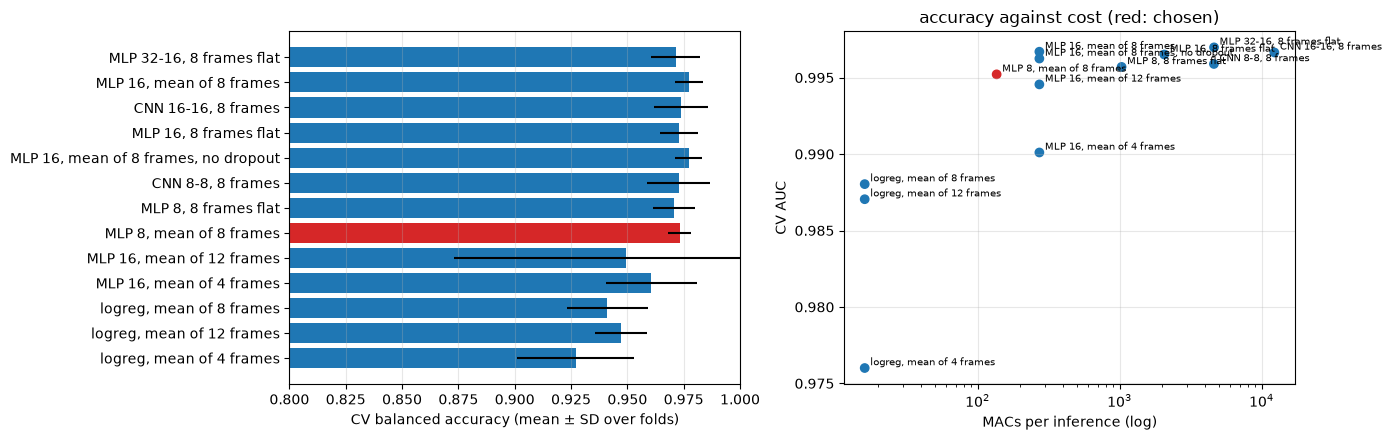

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = cv_table.sort_values("AUC").index
colors = ["C3" if n == B_CHOICE else "C0" for n in order]
axes[0].barh(order, cv_table.loc[order, "balanced_acc"], xerr=cv_table.loc[order, "bacc_sd"], color=colors)
axes[0].set_xlim(0.8, 1.0); axes[0].set_xlabel("CV balanced accuracy (mean ± SD over folds)")
axes[0].grid(axis="x", alpha=0.3)
axes[1].scatter(cv_table["MACs"], cv_table["AUC"], c=["C3" if n == B_CHOICE else "C0" for n in cv_table.index])
for n, r in cv_table.iterrows():
    axes[1].annotate(n, (r["MACs"], r["AUC"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_xlabel("MACs per inference (log)"); axes[1].set_ylabel("CV AUC")
axes[1].grid(alpha=0.3); axes[1].set_title("accuracy against cost (red: chosen)")
plt.tight_layout(); plt.show()

## 11. Training the chosen model

The chosen candidate is trained on the train split only, with early stopping on the val loss
(patience 10, best weights restored). The decision threshold stays at 0.5 (the class weights
already balance the two classes); the curve below shows on the val split what moving it would
trade between precision and recall of CLOSE.

model: MLP 8, mean of 8 frames, input (8, 16)


Model: "emg_bin"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 8, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ frame_mean                      │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_56 (Dropout)            │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_close (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 145 (580.00 B)

 Trainable params: 145 (580.00 B)

 Non-trainable params: 0 (0.00 B)

trained 63 epochs, best val loss at epoch 53


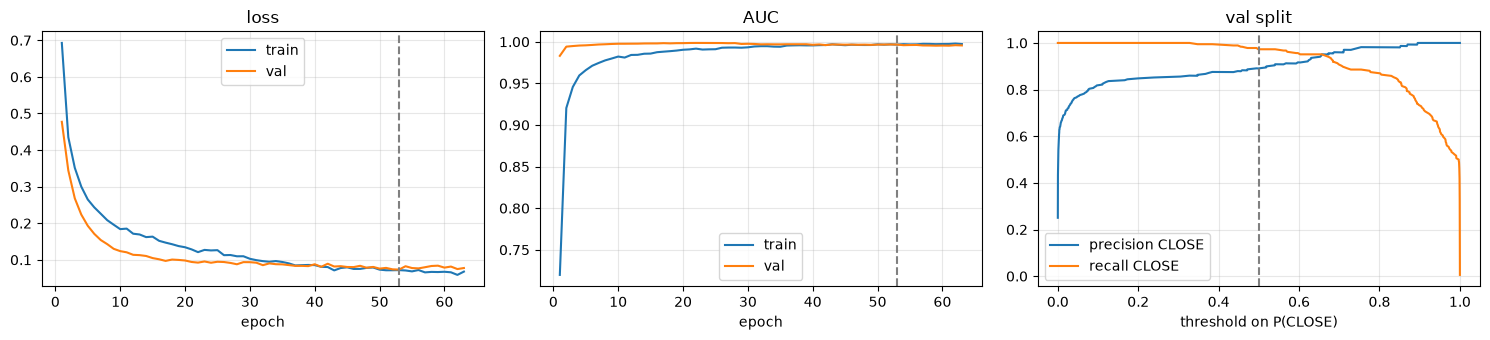

In [21]:
b_cfg = CANDIDATES[B_CHOICE]
if b_cfg["n_frames"] != B_N_FRAMES:
    B_N_FRAMES = b_cfg["n_frames"]
    bX, by, bsrc, buid, b_mu, b_sd = prepare_binary(B_N_FRAMES)
print(f"model: {B_CHOICE}, input {bX['train'].shape[1:]}")

keras.utils.set_random_seed(SEED)
bin_model = build_binary(n_feat=bX["train"].shape[2], name="emg_bin", **b_cfg)
bin_model.summary()
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
b_history = bin_model.fit(bX["train"], by["train"], validation_data=(bX["val"], by["val"]),
                          epochs=200, batch_size=CV_BATCH, class_weight=balanced_weights(by["train"]),
                          callbacks=[early], shuffle=True, verbose=0)
hb = b_history.history
b_best_epoch = int(np.argmin(hb["val_loss"])) + 1
print(f"trained {len(hb['loss'])} epochs, best val loss at epoch {b_best_epoch}")

p_val = bin_model.predict(bX["val"], batch_size=1024, verbose=0)[:, 0]
prec, rec, thr = precision_recall_curve(by["val"], p_val)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
ep = np.arange(1, len(hb["loss"]) + 1)
axes[0].plot(ep, hb["loss"], label="train"); axes[0].plot(ep, hb["val_loss"], label="val")
axes[1].plot(ep, hb["auc"], label="train"); axes[1].plot(ep, hb["val_auc"], label="val")
for ax, t in zip(axes[:2], ("loss", "AUC")):
    ax.axvline(b_best_epoch, color="0.5", ls="--"); ax.set_title(t); ax.set_xlabel("epoch")
    ax.grid(alpha=0.3); ax.legend()
axes[2].plot(thr, prec[:-1], label="precision CLOSE"); axes[2].plot(thr, rec[:-1], label="recall CLOSE")
axes[2].axvline(B_THRESHOLD, color="0.5", ls="--"); axes[2].set_xlabel("threshold on P(CLOSE)")
axes[2].set_title("val split"); axes[2].grid(alpha=0.3); axes[2].legend()
plt.tight_layout(); plt.show()

In [22]:
def binary_metrics(y, p, pred):
    return {"window_acc": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
            "precision_CLOSE": precision_score(y, pred, zero_division=0),
            "recall_CLOSE": recall_score(y, pred), "F1_CLOSE": f1_score(y, pred),
            "AUC": roc_auc_score(y, p)}


def binary_trial_accuracy(pred, y, src, uids):
    # majority vote of the windows of the hold of every trial
    hits = []
    for uid in pd.unique(uids):
        m = (uids == uid) & (src != "REST")
        if m.any():
            hits.append(np.bincount(pred[m], minlength=2).argmax() == y[m][0])
    return float(np.mean(hits)), len(hits)


def plot_binary_confusion(y, pred, title, ax):
    cm = confusion_matrix(y, pred, labels=[0, 1], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:.3f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1], B_CLASSES); ax.set_yticks([0, 1], B_CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)


p_bin = bin_model.predict(bX["test"], batch_size=1024, verbose=0)[:, 0]
pred_bin = (p_bin >= B_THRESHOLD).astype(int)
print(classification_report(by["test"], pred_bin, target_names=B_CLASSES, digits=3))
print({k: round(v, 3) for k, v in binary_metrics(by["test"], p_bin, pred_bin).items()})
acc_t, n_t = binary_trial_accuracy(pred_bin, by["test"], bsrc["test"], buid["test"])
print(f"trial accuracy (majority vote over the hold): {acc_t:.3f} on {n_t} trials")
print("CLOSE predicted, by posture:",
      {l: round(float(pred_bin[bsrc['test'] == l].mean()), 3) for l in B_LABELS})

              precision    recall  f1-score   support

   NOT_CLOSE      0.983     0.966     0.974       552
       CLOSE      0.902     0.951     0.926       184

    accuracy                          0.962       736
   macro avg      0.943     0.958     0.950       736
weighted avg      0.963     0.962     0.962       736

{'window_acc': 0.962, 'balanced_acc': 0.958, 'precision_CLOSE': 0.902, 'recall_CLOSE': 0.951, 'F1_CLOSE': 0.926, 'AUC': 0.994}
trial accuracy (majority vote over the hold): 1.000 on 8 trials
CLOSE predicted, by posture: {'REST': 0.052, 'OPEN': 0.0, 'CLOSE': 0.951}


## 12. Export and quantisation of the binary model

As in Part 1: Keras file, TFLite float32 and full-integer TFLite int8 (calibrated on 500 train
inputs, int8 input and output). The feature parameters the board needs (filter coefficients,
frames, features, calibration rule, mean / SD, threshold) go to `emg_bin/features.json`.

In [23]:
b_keras_path = B_OUT_DIR / "emg_bin.keras"
bin_model.save(b_keras_path)
b_tfl_float = converter_for(bin_model).convert()

b_rep_idx = np.random.default_rng(SEED).choice(len(bX["train"]), size=min(500, len(bX["train"])), replace=False)


def b_representative_data():
    for i in b_rep_idx:
        yield [bX["train"][i:i + 1]]


conv = converter_for(bin_model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = b_representative_data
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8
conv.inference_output_type = tf.int8
b_tfl_int8 = conv.convert()

b_float_path, b_int8_path = B_OUT_DIR / "emg_bin_float32.tflite", B_OUT_DIR / "emg_bin_int8.tflite"
b_float_path.write_bytes(b_tfl_float)
b_int8_path.write_bytes(b_tfl_int8)

(B_OUT_DIR / "features.json").write_text(json.dumps({
    "fs": FS, "channels": CHANNELS, "classes": B_CLASSES, "model": B_CHOICE,
    "positive_class": "CLOSE", "negative_class": "REST or OPEN", "decision_threshold": B_THRESHOLD,
    "filter": {"band_pass_hz": B_BAND_HZ, "band_stop_hz": B_STOP_HZ, "notch_hz_q": B_HARMONIC,
               "sos": B_SOS.tolist(), "form": "scipy sos (b0 b1 b2 a0 a1 a2) per section, causal, in this order"},
    "frame_len": FRAME_LEN, "hop": HOP, "n_frames": B_N_FRAMES, "threshold_uv": B_THRESHOLD_UV,
    "features": B_FEATURES, "feature_order": b_feat_names,
    "amplitude_transform": "log1p (MAV, WL); ZC, SSC divided by frame_len",
    "calibration": {"rule": "subtract the mean frame features of a rest recording of the session",
                    "rest_s": "about 10 (calibration rest of the protocol)", "skip_s": CAL_SKIP_S,
                    "session_baselines": {s: b[:, B_FEAT_IDX].reshape(-1).tolist() for s, b in B_BASE.items()}},
    "mean": b_mu.tolist(), "sd": b_sd.tolist(), "split": str(SPLIT_DIR), "seed": SEED}, indent=2),
    encoding="utf-8")

p_bfloat, ms_bfloat, _, _ = run_tflite(b_tfl_float, bX["test"])
p_bint8, ms_bint8, b_inp8, b_out8 = run_tflite(b_tfl_int8, bX["test"])
p_bfloat, p_bint8 = p_bfloat[:, 0], p_bint8[:, 0]
pred_bfloat, pred_bint8 = (p_bfloat >= B_THRESHOLD).astype(int), (p_bint8 >= B_THRESHOLD).astype(int)
print("int8 input quantisation (scale, zero point):", b_inp8["quantization"])
print("int8 output quantisation (scale, zero point):", b_out8["quantization"])
print(f"sizes: Keras {b_keras_path.stat().st_size / 1024:.1f} kB, TFLite float32 {len(b_tfl_float) / 1024:.1f} kB, "
      f"TFLite int8 {len(b_tfl_int8) / 1024:.1f} kB")
print(f"int8 agrees with Keras on {(pred_bint8 == pred_bin).mean():.3f} of the test windows, "
      f"max |P difference| {np.abs(p_bint8 - p_bin).max():.3f}")

Saved artifact at 'C:\Users\Gabri\AppData\Local\Temp\tmpqwh3jnkj'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8, 16), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2729132165072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727699242960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727753068240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727753072272: TensorSpec(shape=(), dtype=tf.resource, name=None)


Saved artifact at 'C:\Users\Gabri\AppData\Local\Temp\tmpl0cje70d'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 8, 16), dtype=tf.float32, name='features')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2729132165072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727699242960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727753068240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2727753072272: TensorSpec(shape=(), dtype=tf.resource, name=None)


int8 input quantisation (scale, zero point): (0.03207652270793915, -44)
int8 output quantisation (scale, zero point): (0.00390625, -128)
sizes: Keras 29.5 kB, TFLite float32 2.5 kB, TFLite int8 2.6 kB
int8 agrees with Keras on 0.999 of the test windows, max |P difference| 0.077


C:\File\AeaSapiens\20262027\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
C:\File\AeaSapiens\20262027\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 13. Comparison: Part 1 4-class CNN against the Part 2 binary model

Both models are scored on the same binary test set: the windows of the 8 OPEN and CLOSE test
trials (the Part 1 frames and inputs are identical, so the windows match one to one). The Part 1
model answers with 4 classes; "CLOSE" counts as CLOSE and anything else (REST, OPEN, INDEX) as
NOT_CLOSE. Its AUC uses its CLOSE probability.

### 13.1 Settled windows

In [24]:
keep_old = np.isin(uid_test, b_splits["test"]["trial_uid"].unique()) & (y_test != CLASSES.index("INDEX"))
y_old = (y_test[keep_old] == CLASSES.index("CLOSE")).astype(int)
same_windows = B_N_FRAMES == N_FRAMES and len(y_old) == len(by["test"]) and bool((y_old == by["test"]).all())
print(f"Part 1 binary test windows: {len(y_old)}, Part 2: {len(by['test'])}, identical windows: {same_windows}")

src_old = np.array(CLASSES)[y_test[keep_old]]
uid_old = uid_test[keep_old]
CLOSE_K = CLASSES.index("CLOSE")
entries = {
    "Part 1: 4-class CNN, Keras": (model, None, probs_keras[keep_old, CLOSE_K], (pred_keras[keep_old] == CLOSE_K).astype(int)),
    "Part 1: 4-class CNN, TFLite int8": (model, len(tfl_int8), probs_int8[keep_old, CLOSE_K], (pred_int8[keep_old] == CLOSE_K).astype(int)),
    f"Part 2: {B_CHOICE}, Keras": (bin_model, None, p_bin, pred_bin),
    f"Part 2: {B_CHOICE}, TFLite int8": (bin_model, len(b_tfl_int8), p_bint8, pred_bint8),
}
rows = []
for name, (m, size, p, pred) in entries.items():
    yy, ss, uu = (y_old, src_old, uid_old) if name.startswith("Part 1") else (by["test"], bsrc["test"], buid["test"])
    r = {"params": m.count_params(), "MACs": count_macs(m),
         "int8_kB": None if size is None else round(size / 1024, 1)}
    r.update({k: round(v, 3) for k, v in binary_metrics(yy, p, pred).items()})
    r["trial_acc"] = round(binary_trial_accuracy(pred, yy, ss, uu)[0], 3)
    rows.append(pd.Series(r, name=name))
final_comparison = pd.DataFrame(rows)
final_comparison

Part 1 binary test windows: 736, Part 2: 736, identical windows: True


,params,MACs,int8_kB,window_acc,balanced_acc,precision_CLOSE,recall_CLOSE,F1_CLOSE,AUC,trial_acc
"Part 1: 4-class CNN, Keras",11524.0,64768.0,NaN,0.787,0.726,0.569,0.603,0.586,0.909,0.75
"Part 1: 4-class CNN, TFLite int8",11524.0,64768.0,21.3,0.789,0.722,0.578,0.587,0.582,0.897,0.75
"Part 2: MLP 8, mean of 8 frames, Keras",145.0,136.0,NaN,0.962,0.958,0.902,0.951,0.926,0.994,1.00
"Part 2: MLP 8, mean of 8 frames, TFLite int8",145.0,136.0,2.6,0.961,0.957,0.897,0.951,0.923,0.994,1.00


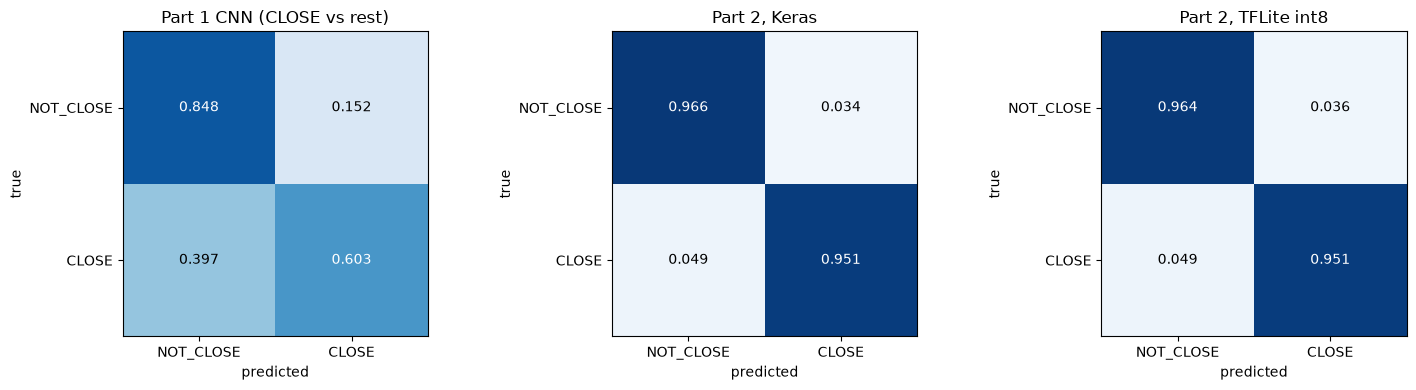

share of windows predicted CLOSE, by true posture:
       Part 1 CNN  Part 2 Keras  Part 2 int8
REST        0.228         0.052        0.054
OPEN        0.000         0.000        0.000
CLOSE       0.603         0.951        0.951


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_binary_confusion(y_old, entries["Part 1: 4-class CNN, Keras"][3], "Part 1 CNN (CLOSE vs rest)", axes[0])
plot_binary_confusion(by["test"], pred_bin, "Part 2, Keras", axes[1])
plot_binary_confusion(by["test"], pred_bint8, "Part 2, TFLite int8", axes[2])
plt.tight_layout(); plt.show()

print("share of windows predicted CLOSE, by true posture:")
print(pd.DataFrame({
    "Part 1 CNN": pd.Series(entries["Part 1: 4-class CNN, Keras"][3]).groupby(src_old).mean(),
    "Part 2 Keras": pd.Series(pred_bin).groupby(bsrc["test"]).mean(),
    "Part 2 int8": pd.Series(pred_bint8).groupby(bsrc["test"]).mean()}).loc[list(B_LABELS)].round(3).to_string())

### 13.2 Streaming over whole test trials

On the board the model runs every 64 ms on whatever the hand is doing, including the cue and the
first moments of every movement, which the settled windows above leave out. Here both models run
over every hop of the 8 OPEN/CLOSE test trials (cue, hold and rest), as they would in real time.
A decision is placed at the last sample of its input. Measured:

- **false CLOSE**: share of decisions that say CLOSE while the label is REST or OPEN (including
  the first 0.5 s after a change);
- **CLOSE held**: share of CLOSE decisions during the CLOSE holds;
- **onset delay**: from the start of a CLOSE hold to the first CLOSE decision;
- **release delay**: from the end of a CLOSE hold to the first NOT_CLOSE decision.

In [26]:
def stream_part1(tr):
    f = frame_features(sliding_window_view(causal_filter(tr[CHANNELS].to_numpy(float)), FRAME_LEN, axis=0)[::HOP])
    W = (sliding_window_view(f, N_FRAMES, axis=0).transpose(0, 2, 1) - mu) / sd
    probs = model.predict(W.astype(np.float32), batch_size=1024, verbose=0)
    t_end = (np.arange(len(W)) + N_FRAMES - 1) * HOP + FRAME_LEN
    return t_end, probs[:, CLOSE_K], (probs.argmax(1) == CLOSE_K).astype(int)


def stream_part2(tr):
    x = filter_with(B_SOS, tr[CHANNELS].to_numpy(float))
    F = frame_feature_array(sliding_window_view(x, FRAME_LEN, axis=0)[::HOP], B_THRESHOLD_UV)
    F = (F - B_BASE[tr["session"].iloc[0]])[:, :, B_FEAT_IDX].reshape(len(F), -1)
    W = (sliding_window_view(F, B_N_FRAMES, axis=0).transpose(0, 2, 1) - b_mu) / b_sd
    p = bin_model.predict(W.astype(np.float32), batch_size=1024, verbose=0)[:, 0]
    t_end = (np.arange(len(W)) + B_N_FRAMES - 1) * HOP + FRAME_LEN
    return t_end, p, (p >= B_THRESHOLD).astype(int)


streams = {"Part 1 CNN": stream_part1, "Part 2": stream_part2}
stream_out = {name: {} for name in streams}
stats = {name: {"false": [], "held": [], "onset": [], "release": []} for name in streams}
for uid, tr in b_splits["test"].groupby("trial_uid", sort=False):
    labels = tr["label"].to_numpy()
    hold = np.flatnonzero(tr["phase"].to_numpy() == "HOLD")
    gesture = labels[hold[0]]
    for name, fn in streams.items():
        t_end, p, dec = fn(tr)
        stream_out[name][uid] = (t_end, p, dec)
        lab_now = labels[t_end - 1]
        neg = np.isin(lab_now, ["REST", "OPEN"])
        stats[name]["false"].append(dec[neg])
        if gesture == "CLOSE":
            in_hold = (t_end - 1 >= hold[0]) & (t_end - 1 <= hold[-1])
            stats[name]["held"].append(dec[in_hold])
            on = np.flatnonzero(in_hold & (dec == 1))
            stats[name]["onset"].append((t_end[on[0]] - 1 - hold[0]) / FS if len(on) else np.nan)
            off = np.flatnonzero((t_end - 1 > hold[-1]) & (dec == 0))
            stats[name]["release"].append((t_end[off[0]] - 1 - hold[-1]) / FS if len(off) else np.nan)

stream_table = pd.DataFrame({name: {
    "false CLOSE (%)": 100 * np.concatenate(s["false"]).mean(),
    "CLOSE held (%)": 100 * np.concatenate(s["held"]).mean(),
    "onset delay, median (s)": np.nanmedian(s["onset"]),
    "onset delay, max (s)": np.nanmax(s["onset"]),
    "release delay, median (s)": np.nanmedian(s["release"]),
    "release delay, max (s)": np.nanmax(s["release"]),
} for name, s in stats.items()}).T
print(f"{b_splits['test']['trial_uid'].nunique()} test trials, one decision every {HOP / FS * 1e3:.0f} ms")
stream_table.round(2)

8 test trials, one decision every 64 ms


,false CLOSE (%),CLOSE held (%),"onset delay, median (s)","onset delay, max (s)","release delay, median (s)","release delay, max (s)"
Part 1 CNN,14.67,49.21,1.21,3.36,0.34,0.69
Part 2,7.47,82.94,0.57,0.86,0.57,0.76


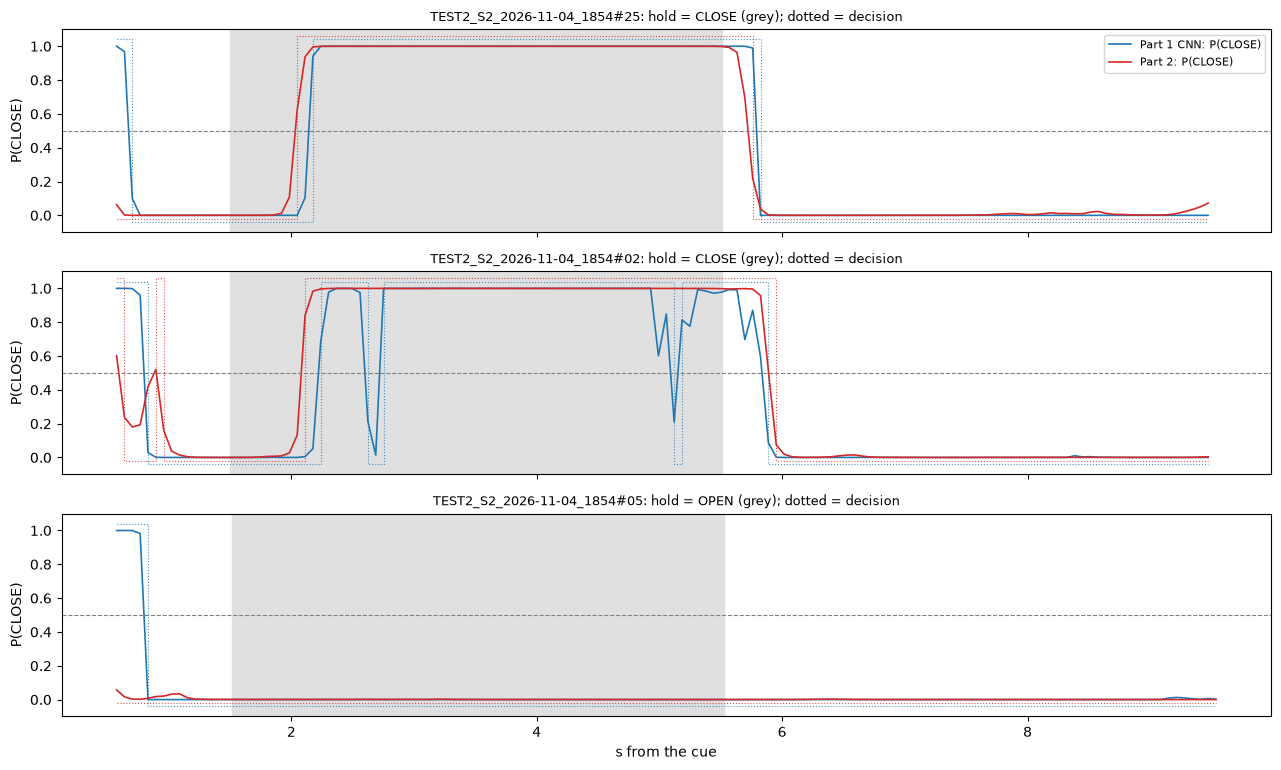

In [27]:
test_uids = list(b_splits["test"].groupby("trial_uid", sort=False).groups)
gest = hold_gesture(b_splits["test"])
show = [u for u in test_uids if gest[u] == "CLOSE"][:2] + [u for u in test_uids if gest[u] == "OPEN"][:1]
fig, axes = plt.subplots(len(show), 1, figsize=(13, 2.6 * len(show)), sharex=True)
for ax, uid in zip(np.atleast_1d(axes), show):
    tr = b_splits["test"][b_splits["test"]["trial_uid"] == uid]
    hold = np.flatnonzero(tr["phase"].to_numpy() == "HOLD")
    ax.axvspan(hold[0] / FS, hold[-1] / FS, color="0.88", zorder=0)
    for name, color in (("Part 1 CNN", "C0"), ("Part 2", "C3")):
        t_end, p, dec = stream_out[name][uid]
        ax.plot(t_end / FS, p, color=color, lw=1.2, label=f"{name}: P(CLOSE)")
        ax.step(t_end / FS, dec * 1.08 - 0.04 + (0.02 if name == "Part 2" else 0), where="post",
                color=color, lw=0.8, ls=":", alpha=0.8)
    ax.axhline(B_THRESHOLD, color="0.5", lw=0.8, ls="--")
    ax.set_ylim(-0.1, 1.1); ax.set_ylabel("P(CLOSE)")
    ax.set_title(f"{uid}: hold = {gest[uid]} (grey); dotted = decision", fontsize=9)
np.atleast_1d(axes)[0].legend(loc="upper right", fontsize=8)
np.atleast_1d(axes)[-1].set_xlabel("s from the cue")
plt.tight_layout(); plt.show()

### 13.3 Cost on the board

Rough operation counts per second of signal (4 channels, 250 Hz, one decision every 16 samples).
A biquad is counted as 5 multiply-accumulates, a feature as about one operation per sample of
the frame. As a reference, the main core of the Arduino GIGA R1 runs at 480 MHz; the share
below assumes one operation per clock cycle, which is pessimistic for a Cortex-M7 with FPU.

In [28]:
MCU_CLOCK_HZ = 480e6     # Arduino GIGA R1 main core (Cortex-M7), from the board datasheet
decisions_per_s = FS / HOP
cost = {}
for name, n_biquads, n_feat, m in (("Part 1 CNN", len(SOS), len(FEATURES), model),
                                   ("Part 2", len(B_SOS), len(B_FEATURES), bin_model)):
    filt_ops = n_biquads * 5 * len(CHANNELS) * FS
    feat_ops = n_feat * FRAME_LEN * len(CHANNELS) * decisions_per_s
    model_ops = count_macs(m) * decisions_per_s
    total = filt_ops + feat_ops + model_ops
    cost[name] = {"filter (kop/s)": filt_ops / 1e3, "features (kop/s)": feat_ops / 1e3,
                  "model (kop/s)": model_ops / 1e3, "total (kop/s)": total / 1e3,
                  "share of 480 MHz (%)": 100 * total / MCU_CLOCK_HZ}
pd.DataFrame(cost).T.round(2)

,filter (kop/s),features (kop/s),model (kop/s),total (kop/s),share of 480 MHz (%)
Part 1 CNN,30.0,10.0,1012.00,1052.00,0.22
Part 2,35.0,8.0,2.12,45.12,0.01


## 14. Notes on Part 2

- **What made the difference.** Almost all the gain comes from the signal side, not from the
  network: the wider mains filter (section 8.2) and the per-session calibration (8.5). Once the
  features are clean, every architecture in section 10 scores within a few points of the others,
  and the smallest ones are as good as the CNN. That is why the selection rule picks a cheap one.
- **Calibration is now part of the pipeline.** The board must record a rest of about 10 s after
  the electrodes are placed (as the protocol's calibration rest does), average the features and
  subtract them from then on. Without it the model is not valid. Section 8.6 shows the score
  without calibration.
- **Small data.** Two sessions of one subject on one day; 8 test trials. The numbers are a first
  look. A session on another day, with the electrodes placed again, is the real test, and the
  calibration step is what should make that work.
- **Mains.** About 1 mV of 50 Hz on ch1 and ch2 (0.2-0.6 mV on ch4) is far more than the EMG;
  the band-stop copes with it, but better contact or the new cables should lower it at the
  source. If the noise level changes a lot, `B_STOP_HZ` can stay but `B_THRESHOLD_UV` (ZC/SSC
  dead band) may need tuning.
- **Where the errors are.** OPEN is never taken for CLOSE; the false closes come from REST (about
  5% of the settled rest windows; 7.5% in 13.2, where the first 0.5 s after each change count too).
- **File size.** At 145 weights the int8 file (2.6 kB) is not smaller than the float32 one: it
  is mostly flatbuffer overhead and quantisation parameters. The point of int8 here is integer-only
  arithmetic, not size.
- **Latency.** The input spans 576 ms, so a decision lags the movement (onset and release delays
  in 13.2). If the hand feels slow, the 4-frame variants in section 10 trade a little accuracy for
  a shorter window; a vote over the last decisions can remove the isolated flips.
- **Precision against recall.** `B_THRESHOLD` moves the balance: above 0.5, fewer false closes
  but later and less steady CLOSE detection (curve in section 11).
- **Files.** `emg_bin/emg_bin_int8.tflite` (TensorFlow Lite Micro) and `emg_bin/features.json`
  (filter coefficients, features, calibration rule, mean / SD). The network is small enough to be
  written out by hand in C as well, without TensorFlow Lite Micro.